# Unit 7 — Mengkonstruksi Data
**Kode unit:** J.62DMI00.009.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini membangun **16 fitur** sesuai rencana Unit 5 dan **variabel target**, membagi data secara kronologis (80/20) dengan *purging*, menerapkan *winsorization* berbasis data latih, dan menjalankan **uji kebocoran data** (*point-in-time test*) sebelum data diserahkan ke tahap pemodelan.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

In [2]:
clean = pd.read_csv(PROC / 'market_clean.csv', parse_dates=['Date'])
plan = pd.read_csv(REP / 'feature_plan.csv')
FEATURES = plan.fitur.tolist()
print(f'Data bersih: {len(clean):,} hari bursa | fitur direncanakan: {len(FEATURES)}')

Data bersih: 3,956 hari bursa | fitur direncanakan: 16


## 1. Fungsi konstruksi fitur dan target

In [3]:
def pct(s):
    return s.pct_change() * 100


def build_features(d):
    # Semua fitur pada baris t hanya memakai nilai hingga hari t
    d = d.sort_values('Date').reset_index(drop=True)
    f = pd.DataFrame({'Date': d.Date})
    f['ihsg_ret'] = pct(d.IHSG)
    for k in (1, 2, 3):
        f[f'ihsg_ret_lag{k}'] = f.ihsg_ret.shift(k)
    f['ihsg_mom_5d'] = (d.IHSG / d.IHSG.shift(5) - 1) * 100
    f['ihsg_dist_ma5'] = (d.IHSG / d.IHSG.rolling(5).mean() - 1) * 100
    f['ihsg_dist_ma20'] = (d.IHSG / d.IHSG.rolling(20).mean() - 1) * 100
    f['ihsg_vol_10d'] = f.ihsg_ret.rolling(10).std()
    f['sp500_ret'] = pct(d.SP500)
    f['sp500_ret_lag1'] = f.sp500_ret.shift(1)
    f['vix_level'] = d.VIX
    f['vix_chg'] = pct(d.VIX)
    f['oil_ret'] = pct(d.OIL)
    f['gold_ret'] = pct(d.GOLD)
    f['usdidr_ret'] = pct(d.USDIDR)
    f['rate_spread'] = d.BI_rate_pit - d.US_rate_pit
    return f


def build_target(d):
    nxt = d.IHSG.shift(-1)
    ret_next = (nxt / d.IHSG - 1) * 100
    y = (ret_next > 0).astype(float).where(nxt.notna())
    return y, ret_next


feat = build_features(clean)
assert [c for c in feat.columns if c != 'Date'] == FEATURES, 'Fitur tidak sesuai rencana Unit 5'
y, ret_next = build_target(clean)
data = feat.assign(ret_next=ret_next, y=y)
n_before = len(data)
data = data.dropna().reset_index(drop=True)
data['y'] = data.y.astype(int)
print(f'Baris dengan fitur & target lengkap: {len(data):,} (dikeluarkan {n_before - len(data)} baris: '
      f'jendela bergulir di awal + hari terakhir tanpa target)')
display(data.head())

Baris dengan fitur & target lengkap: 3,936 (dikeluarkan 20 baris: jendela bergulir di awal + hari terakhir tanpa target)


,Date,ihsg_ret,ihsg_ret_lag1,ihsg_ret_lag2,ihsg_ret_lag3,ihsg_mom_5d,ihsg_dist_ma5,ihsg_dist_ma20,ihsg_vol_10d,sp500_ret,sp500_ret_lag1,vix_level,vix_chg,oil_ret,gold_ret,usdidr_ret,rate_spread,ret_next,y
0,2010-03-01,0.2213,-1.1779,-0.1639,0.7561,0.0117,-0.4494,0.2272,0.8649,1.1578,-0.2081,19.2600,-4.1791,0.6780,0.9027,0.5345,6.3700,0.8579,1
1,2010-03-02,0.8579,0.2213,-1.1779,-0.1639,0.4808,0.3083,1.1088,0.8531,0.2330,1.1578,19.0600,-1.0384,1.2452,1.7087,-2.1385,6.3700,-0.3688,0
2,2010-03-03,-0.3688,0.8579,0.2213,-1.1779,-0.6410,0.0674,0.7619,0.7126,0.0429,0.2330,18.8300,-1.2067,1.4935,0.5102,-0.3822,6.3700,-0.0563,0
3,2010-03-04,-0.0563,-0.3688,0.8579,0.2213,-0.5339,0.1186,0.7822,0.6459,0.3736,0.0429,18.7200,-0.5842,-0.8161,-0.8839,1.9630,6.3700,0.5116,1
4,2010-03-05,0.5116,-0.0563,-0.3688,0.8579,1.1667,0.3978,1.3266,0.6069,1.4007,0.3736,17.4200,-6.9444,1.6083,0.1942,-4.6147,6.3700,1.8489,1


## 2. Uji kebocoran data: *point-in-time test*

Jika sebuah fitur diam-diam memakai data masa depan, nilainya pada tanggal $T$ akan **berubah** ketika data setelah
$T$ dihapus. Uji ini menghitung ulang fitur hanya dengan data hingga $T$ untuk 40 tanggal acak, lalu membandingkannya
dengan fitur dari data lengkap. Hasil yang identik membuktikan tidak ada *look-ahead* dalam konstruksi fitur.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
sample_dates = pd.to_datetime(rng.choice(data.Date.values, 40, replace=False))
mismatch = []
for T in sample_dates:
    partial = build_features(clean[clean.Date <= T])
    a = partial.loc[partial.Date == T, FEATURES].to_numpy(dtype=float)
    b = feat.loc[feat.Date == T, FEATURES].to_numpy(dtype=float)
    if not np.allclose(a, b, equal_nan=True):
        mismatch.append(T)
pit_passed = len(mismatch) == 0
print(f'Tanggal diuji: {len(sample_dates)} | tidak cocok: {len(mismatch)} → {"LULUS" if pit_passed else "GAGAL"}')
assert pit_passed

# Kontrol negatif: fitur yang sengaja dibuat bocor (return IHSG besok) harus tertangkap oleh uji yang sama
leaky = lambda d: build_features(d).assign(bocor=pct(d.sort_values('Date').IHSG).shift(-1).values)
T = sample_dates[0]
caught = not np.allclose(leaky(clean[clean.Date <= T]).loc[lambda f: f.Date == T, 'bocor'].to_numpy(dtype=float),
                         leaky(clean).loc[lambda f: f.Date == T, 'bocor'].to_numpy(dtype=float), equal_nan=True)
print(f'Kontrol negatif (fitur bocor sengaja) terdeteksi: {caught}')

Tanggal diuji: 40 | tidak cocok: 0 → LULUS
Kontrol negatif (fitur bocor sengaja) terdeteksi: True


## 3. Pembagian data kronologis dengan *purging*

80% hari bursa paling awal → data latih, 20% terakhir → data uji. Target baris latih terakhir memakai harga
penutupan hari uji pertama, sehingga **satu baris latih terakhir dibuang** (*purging*) agar informasi label tidak
tumpang tindih dengan periode uji.

,Set,Periode,Jumlah hari,Proporsi Naik,Rata-rata return besok (%)
0,Latih,01 Mar 2010 – 20 Jan 2023,3148,0.5464,0.0372
1,Uji,25 Jan 2023 – 26 May 2026,787,0.5273,-0.0081


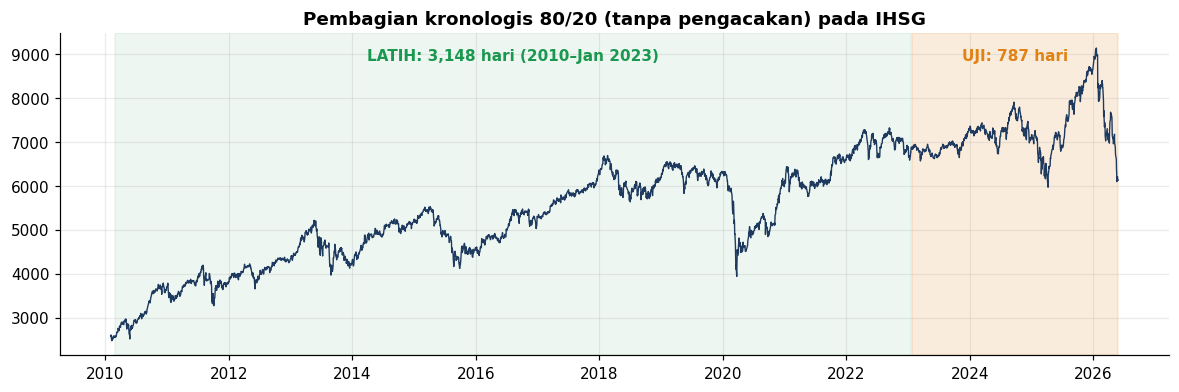

In [5]:
n_split = int(round(len(data) * 0.8))
PURGE = 1
train = data.iloc[:n_split - PURGE].copy()
test = data.iloc[n_split:].copy()
assert train.Date.max() < test.Date.min()

split = pd.DataFrame({
    'Set': ['Latih', 'Uji'],
    'Periode': [f'{train.Date.min():%d %b %Y} – {train.Date.max():%d %b %Y}', f'{test.Date.min():%d %b %Y} – {test.Date.max():%d %b %Y}'],
    'Jumlah hari': [len(train), len(test)],
    'Proporsi Naik': [train.y.mean(), test.y.mean()],
    'Rata-rata return besok (%)': [train.ret_next.mean(), test.ret_next.mean()],
})
display(split)

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(clean.Date, clean.IHSG, color=C_NAVY, lw=0.9)
ax.axvspan(train.Date.min(), train.Date.max(), color=C_UP, alpha=0.08)
ax.axvspan(test.Date.min(), test.Date.max(), color=C_ACCENT, alpha=0.15)
ymax = clean.IHSG.max()
ax.text(train.Date.min() + (train.Date.max() - train.Date.min()) / 2, ymax * 0.97,
        f'LATIH: {len(train):,} hari ({train.Date.min():%Y}–{train.Date.max():%b %Y})', ha='center', color=C_UP, fontweight='bold')
ax.text(test.Date.min() + (test.Date.max() - test.Date.min()) / 2, ymax * 0.97,
        f'UJI: {len(test):,} hari', ha='center', color=C_ACCENT, fontweight='bold')
ax.set_title('Pembagian kronologis 80/20 (tanpa pengacakan) pada IHSG')
plt.savefig(FIG / '07_train_test_split.png')
plt.show()

## 4. *Winsorization* berbasis data latih

Return keuangan berekor tebal (Unit 3). Agar beberapa hari ekstrem tidak mendominasi model linear/SVM, setiap fitur
dibatasi pada **persentil 1% dan 99% data latih**. Batas dihitung **hanya dari data latih** lalu diterapkan ke data
uji, dan disimpan untuk dipakai ulang saat model digunakan. `rate_spread` tidak dibatasi karena berupa variabel level
kebijakan yang tidak berekor tebal.

In [6]:
CLIP = [c for c in FEATURES if c != 'rate_spread']
lower, upper = train[CLIP].quantile(0.01), train[CLIP].quantile(0.99)
clip_stats = pd.DataFrame({
    'batas_bawah': lower, 'batas_atas': upper,
    'dipotong_latih': ((train[CLIP] < lower) | (train[CLIP] > upper)).sum(),
    'dipotong_uji': ((test[CLIP] < lower) | (test[CLIP] > upper)).sum(),
})
train[CLIP] = train[CLIP].clip(lower, upper, axis=1)
test[CLIP] = test[CLIP].clip(lower, upper, axis=1)
display(clip_stats)
with open(MOD / 'clip_bounds.json', 'w') as f:
    json.dump({'lower': lower.round(6).to_dict(), 'upper': upper.round(6).to_dict()}, f, indent=2)

,batas_bawah,batas_atas,dipotong_latih,dipotong_uji
ihsg_ret,-3.1771,2.8751,64,16
ihsg_ret_lag1,-3.1771,2.8751,64,16
ihsg_ret_lag2,-3.1771,2.8751,64,16
ihsg_ret_lag3,-3.1771,2.8751,64,16
ihsg_mom_5d,-7.3946,6.3024,64,18
ihsg_dist_ma5,-3.9887,2.9183,64,16
ihsg_dist_ma20,-8.1571,5.8116,64,18
ihsg_vol_10d,0.3169,3.0772,64,16
sp500_ret,-3.2360,2.9676,64,4
sp500_ret_lag1,-3.2360,2.9676,64,4


## 5. Hubungan fitur dengan target (data latih saja)

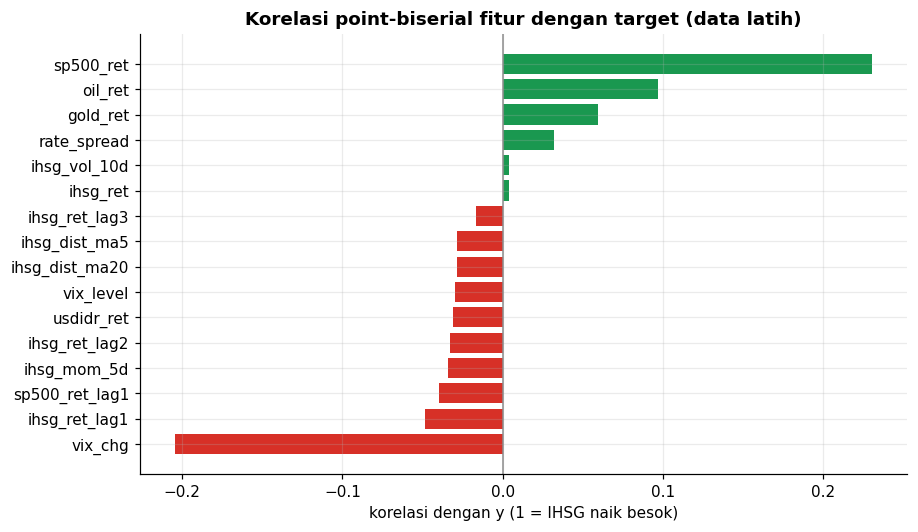

Korelasi absolut maksimum: 0.231 (sp500_ret) — tidak ada fitur yang "terlalu sempurna" (indikasi kebocoran bila > 0,5)


In [7]:
corr = train[FEATURES].corrwith(train.y).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(corr.index, corr.values, color=[C_UP if v > 0 else C_DOWN for v in corr.values])
ax.axvline(0, color=C_GREY, lw=1)
ax.set_title('Korelasi point-biserial fitur dengan target (data latih)')
ax.set_xlabel('korelasi dengan y (1 = IHSG naik besok)')
plt.savefig(FIG / '07_feature_target_corr.png')
plt.show()
print('Korelasi absolut maksimum:', round(corr.abs().max(), 3), f'({corr.abs().idxmax()})',
      '— tidak ada fitur yang "terlalu sempurna" (indikasi kebocoran bila > 0,5)')

In [8]:
cols = ['Date'] + FEATURES + ['ret_next', 'y']
train[cols].to_csv(PROC / 'train.csv', index=False)
test[cols].to_csv(PROC / 'test.csv', index=False)
split_info = {
    'n_train': len(train), 'n_test': len(test), 'purge_rows': PURGE,
    'train_period': [f'{train.Date.min():%Y-%m-%d}', f'{train.Date.max():%Y-%m-%d}'],
    'test_period': [f'{test.Date.min():%Y-%m-%d}', f'{test.Date.max():%Y-%m-%d}'],
    'train_up_share': round(float(train.y.mean()), 4), 'test_up_share': round(float(test.y.mean()), 4),
    'features': FEATURES, 'winsorization': '1%-99% kuantil data latih',
    'pit_test': {'dates_tested': len(sample_dates), 'mismatch': len(mismatch), 'passed': pit_passed,
                 'negative_control_detected': bool(caught)},
}
with open(REP / 'split_info.json', 'w') as f:
    json.dump(split_info, f, indent=2)
display(Markdown(f'''
### Ringkasan Unit 7
- **{len(FEATURES)} fitur** + target biner dibangun dari {len(clean):,} hari bursa bersih.
- **Uji point-in-time LULUS** ({len(sample_dates)} tanggal, 0 selisih); kontrol negatif terdeteksi = {caught}.
- **Latih:** {len(train):,} hari ({train.Date.min():%b %Y} – {train.Date.max():%b %Y}), proporsi naik {train.y.mean():.1%}.
  **Uji:** {len(test):,} hari ({test.Date.min():%b %Y} – {test.Date.max():%b %Y}), proporsi naik {test.y.mean():.1%}.
- Winsorization 1–99% berbasis data latih; batas disimpan di `models/clip_bounds.json`.
- Standardisasi **tidak** dilakukan di sini, melainkan di dalam *pipeline* model (Unit 9) agar tidak bocor antarlipatan validasi.
'''))


### Ringkasan Unit 7
- **16 fitur** + target biner dibangun dari 3,956 hari bursa bersih.
- **Uji point-in-time LULUS** (40 tanggal, 0 selisih); kontrol negatif terdeteksi = True.
- **Latih:** 3,148 hari (Mar 2010 – Jan 2023), proporsi naik 54.6%.
  **Uji:** 787 hari (Jan 2023 – May 2026), proporsi naik 52.7%.
- Winsorization 1–99% berbasis data latih; batas disimpan di `models/clip_bounds.json`.
- Standardisasi **tidak** dilakukan di sini, melainkan di dalam *pipeline* model (Unit 9) agar tidak bocor antarlipatan validasi.
